## 0. Setup

In [1]:
%pip install -q pandas numpy matplotlib statsmodels scikit-learn openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import warnings

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from pandas.tseries.offsets import BDay, MonthEnd

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

In [3]:
# ---------------- Configuration ----------------
RAW_REL = Path("data") / "raw" / "Oil Data.xlsx"
here = Path.cwd()
candidates = [p for base in [here, *here.parents] for p in (base, base / "fe-oil-group-work")]
REPO = next((p for p in candidates if (p / RAW_REL).exists()), None)
assert REPO is not None, f"Can't find {RAW_REL}. Notebook is running in: {here}"

DATA_FILE = REPO / RAW_REL
CLEAN_FILE = REPO / "data" / "clean" / "oil_monthly_clean.csv"
DICTIONARY_FILE = REPO / "data" / "clean" / "oil_monthly_dictionary.csv"
CLEAN_FILE.parent.mkdir(parents=True, exist_ok=True)

# Split by target month (same 114 test months as the shared no-change benchmark)
TRAIN_END = "2004-12-31"
VALID_END = "2014-12-31"          # test = Jan 2015 - Jun 2024

Max_lags = 10
Significance_level = 0.05
random_seed = 42

# Release lag in months: 0 = market price known at the month-end close, 1 = published next month
RELEASE_LAG_MONTHS = {
    "cl1": 0, "cl2": 0, "crack_321": 0, "bdi": 0,
    "production": 1, "inventories": 1, "rig_count": 1,
    "comm_long": 1, "comm_short": 1,
    "cpi_yoy": 1, "ip_index": 1,
    "y3m": 1, "y10y": 1,          # yields in the file are dated one month early (see 2.4)
    "spx": 0, "dxy_ret": 0, "vix": 0,
    "gasoline": 1,
    "dj_oil_gas": 0, "xom": 0, "cop": 0, "cvx": 0, "bp": 0, "shell": 0, "total": 0,
}

Z_OUTLIER = 4
OUTLIER_TREATMENT = "keep"
LARGE_MOVE_SD = 5                 # data check only: flag month-on-month moves above this

# Plotting
C_BLUE, C_ORANGE, C_INK, C_GREY = "#2a78d6", "#eb6834", "#52514e", "#b9b8b3"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.edgecolor": C_GREY, "axes.labelcolor": C_INK, "xtick.color": C_INK, "ytick.color": C_INK,
    "axes.titlesize": 10, "axes.titlelocation": "left", "lines.linewidth": 1.2, "font.size": 8,
})

np.random.seed(random_seed)

## 1. Research question & target

Can macro, industry and positioning data forecast next month's WTI front-month return?

Target: $y_{t+1} = 100\,(CL1_{t+1}/CL1_t - 1)$, month-end to month-end. Monthly frequency, since most of the macro data is monthly.

Also kept: `y_log` (log return, robustness) and `y_tradable` $= 100\,(CL1_{t+1}/CL2_t - 1)$ (trading rule, see 2.6).

*Predictor table: Div.*

## 2. Data cleaning

Output: one row per month-end *t* with next month's return and only data available at *t*. Saved to `data/oil_monthly_clean.csv`.

### 2.1 Load and inspect

In [4]:
SHEETS = ["Industry_D", "Industry_W", "Industry_M", "Macro_M", "StockPrices_M"]
raw = {name: pd.read_excel(DATA_FILE, sheet_name=name) for name in SHEETS}

checks = []
for name, frame in raw.items():
    dated = frame.dropna(subset=["Date"])
    checks.append({"sheet": name, "rows": len(frame), "rows without a date": int(frame["Date"].isna().sum()),
                   "duplicate dates": int(dated["Date"].duplicated().sum()),
                   "newest first": dated["Date"].is_monotonic_decreasing,
                   "first date": dated["Date"].min().date(), "last date": dated["Date"].max().date(),
                   "missing cells": int(dated.drop(columns="Date").isna().sum().sum())})
pd.DataFrame(checks).set_index("sheet")

,rows,rows without a date,duplicate dates,newest first,first date,last date,missing cells
sheet,,,,,,,
Industry_D,9226,534,0,True,1990-01-02,2024-07-30,398
Industry_W,1803,0,0,True,1990-01-05,2024-07-19,260
Industry_M,355,0,0,True,1994-12-30,2024-06-28,0
Macro_M,355,0,0,True,1994-12-31,2024-06-30,0
StockPrices_M,355,0,0,True,1994-12-30,2024-06-28,127


In [5]:
daily = raw["Industry_D"].dropna(subset=["Date"]).sort_values("Date").set_index("Date")
weekly = raw["Industry_W"].sort_values("Date").set_index("Date")
ind_m = raw["Industry_M"].sort_values("Date").set_index("Date")
macro_m = raw["Macro_M"].sort_values("Date").set_index("Date")
stocks_m = raw["StockPrices_M"].sort_values("Date").set_index("Date")

for frame in (daily, weekly, ind_m, macro_m, stocks_m):
    assert frame.index.is_unique

### 2.2 Brent and the daily sheet
`Industry_D` has 534 rows with a Brent value and no date. Comparing month-end values from the daily sheet with `Industry_M`:

In [6]:
pairs = {"CL1": "CL1", "CL2": "CL2", "Brent": "Brent ", "CRKS321C Index": "CRKS321C Index",
         "BDIY Index": "Baltic Dry Index"}
daily_me = daily.resample("ME").last()
monthly_me = ind_m.copy()
monthly_me.index = monthly_me.index + MonthEnd(0)

align = []
for d_col, m_col in pairs.items():
    both = pd.concat([daily_me[d_col], monthly_me[m_col]], axis=1, keys=["daily", "monthly"]).dropna()
    align.append({"series": d_col, "months": len(both),
                  "exact matches": int(((both["daily"] - both["monthly"]).abs() < 1e-9).sum()),
                  "May 2024 daily": both.loc["2024-05-31", "daily"],
                  "May 2024 monthly": both.loc["2024-05-31", "monthly"]})
pd.DataFrame(align).set_index("series")

,months,exact matches,May 2024 daily,May 2024 monthly
series,,,,
CL1,355,355,76.990,76.990
CL2,355,355,76.730,76.730
Brent,355,0,77.520,81.620
CRKS321C Index,355,1,21.641,19.547
BDIY Index,355,5,"1,813.000","1,815.000"


In [7]:
assert (daily_me["CL1"].reindex(monthly_me.index) - monthly_me["CL1"]).abs().max() < 1e-9
assert (daily_me["CL2"].reindex(monthly_me.index) - monthly_me["CL2"]).abs().max() < 1e-9

CL1 and CL2 match every month. Brent, crack and BDI in the daily sheet are shifted against the dates (e.g. Brent end-May 2024: 77.52 vs 81.62).

- **Brent is dropped**: the data has a known error, and it would duplicate CL1 anyway.
- Crack and BDI are taken from `Industry_M` (correct month-end values).
- The daily sheet is only used for CL1/CL2 checks. Don't use daily crack/BDI without re-aligning.

### 2.3 Weekly vs monthly definitions

In [8]:
weekly_last = weekly.resample("ME").last()
defs = pd.DataFrame({
    "monthly / weekly (median ratio)": {
        "Production": (monthly_me["Daily Production"] / weekly_last["Weekly Prod Crude"]).median(),
        "Rig count": (monthly_me["Rig Count"] / weekly_last["Weekly Rig Count"]).median(),
        "Commercial long": (monthly_me["Commercial Long"] / weekly_last["Weekly Commercial Long"]).median(),
        "Open interest": (monthly_me["Total Open Interest"] / weekly_last["Weekly Total Open Interest"]).median(),
    }})
inv_chg_m = monthly_me["Inventories"].diff()
crude_chg_w = weekly["Weekly change in Crude Stock"].resample("ME").sum()
defs.loc["Inventories (corr, monthly change vs summed weekly)"] = \
    inv_chg_m.corr(crude_chg_w.reindex(inv_chg_m.index))
defs

,monthly / weekly (median ratio)
Production,1.000
Rig count,2.352
Commercial long,1.853
Open interest,1.775
"Inventories (corr, monthly change vs summed weekly)",0.928


Only production matches. Rigs (~2.4x) and COT (~1.8x) use different definitions, and monthly inventories include products. We use the monthly sheets only.

### 2.4 Monthly table
All dates moved to calendar month-end (`Macro_M` uses month-end, the others the last trading day), then joined.

In [9]:
RENAME = {
    "Industry_M": {"CL1": "cl1", "CL2": "cl2", "CRKS321C Index": "crack_321",
                   "Baltic Dry Index": "bdi", "Daily Production": "production", "Inventories": "inventories",
                   "Rig Count": "rig_count", "Commercial Long": "comm_long", "Commercial Short": "comm_short"},
    "Macro_M": {"CPI YOY %": "cpi_yoy", "3M Yield": "y3m", "10Y Yield": "y10y",
                "IndustrialProduction Index": "ip_index", "SPX": "spx", "DXY returns": "dxy_ret", "VIX": "vix"},
    "StockPrices_M": {"Gasoline All Grades": "gasoline", "Dow Jones US Oil&Gas Index": "dj_oil_gas",
                      "ExxonMobil": "xom", "ConocoPhilips": "cop", "Chevron": "cvx", "BP ": "bp",
                      "Shell": "shell", "TotalEnergies": "total"},
}
UNITS = {"cl1": "$/bbl", "cl2": "$/bbl", "crack_321": "$/bbl", "bdi": "index",
         "production": "thousand bbl/day", "inventories": "thousand bbl (crude + products)",
         "rig_count": "rigs", "comm_long": "contracts", "comm_short": "contracts",
         "cpi_yoy": "% YoY", "y3m": "% p.a.", "y10y": "% p.a.",
         "ip_index": "index", "spx": "index", "dxy_ret": "decimal monthly return", "vix": "index points",
         "gasoline": "$/gallon", "dj_oil_gas": "index", "xom": "$", "cop": "$", "cvx": "$", "bp": "$",
         "shell": "$", "total": "$"}

parts = []
for name, frame in [("Industry_M", ind_m), ("Macro_M", macro_m), ("StockPrices_M", stocks_m)]:
    part = frame.rename(columns=RENAME[name])[list(RENAME[name].values())].copy()
    part.index = part.index + MonthEnd(0)
    assert part.index.is_unique, f"{name}: two rows in the same month"
    parts.append(part)

ref = pd.concat(parts, axis=1, join="outer").sort_index()
ref.index.name = "date"

assert ref.index.equals(pd.date_range(ref.index.min(), ref.index.max(), freq="ME")), "missing or extra month"
assert ref.index.is_month_end.all()
assert set(ref.columns) == set(RELEASE_LAG_MONTHS) == set(UNITS)
print(f"{len(ref)} months, {ref.index.min().date()} to {ref.index.max().date()}, {ref.shape[1]} series")

assert (ind_m["Total Open Interest"] == ind_m["Commercial Long"] + ind_m["Commercial Short"]).all()

missing = ref.isna().sum()
missing[missing > 0].to_frame("missing months")

355 months, 1994-12-31 to 2024-06-30, 24 series


,missing months
shell,127


- Shell has gaps (no data before July 2005). Left as missing.
- `Total Open Interest` is dropped: every cell is the formula Long + Short, so it is not real open interest and is perfectly collinear with them.
- Treasury yields: a teammate's check against US Treasury data found the yield labelled month *t* is the rate at the end of *t+1*. Values are kept, but they get a one-month lag in 2.7.

### 2.5 April 2020

In [10]:
daily.loc["2020-04-15":"2020-05-01", ["CL1", "CL2"]].T

Date,2020-04-15,2020-04-16,2020-04-17,2020-04-20,2020-04-21,2020-04-22,2020-04-23,2020-04-24,2020-04-27,2020-04-28,2020-04-29,2020-04-30,2020-05-01
CL1,19.870,19.870,18.270,-37.630,10.010,13.780,16.500,16.940,12.780,12.340,15.060,18.840,19.780
CL2,26.040,25.530,25.030,20.430,11.570,20.690,21.440,21.220,18.080,17.600,19.120,21.850,22.290


In [11]:
ref.loc["2020-01-31":"2020-07-31", ["cl1", "cl2"]].assign(
    cl1_pct_change=lambda d: 100 * d["cl1"].pct_change())

,cl1,cl2,cl1_pct_change
date,,,
2020-01-31,51.560,51.680,NaN
2020-02-29,44.760,44.940,-13.189
2020-03-31,20.480,24.510,-54.245
2020-04-30,18.840,21.850,-8.008
2020-05-31,35.490,35.840,88.376
2020-06-30,39.270,39.340,10.651
2020-07-31,40.270,40.570,2.546


In [12]:
assert (ref["cl1"] > 0).all() and (ref["cl2"] > 0).all()
print(f"Lowest month-end CL1: {ref['cl1'].min():.2f} ({ref['cl1'].idxmin():%b %Y})")

Lowest month-end CL1: 11.22 (Nov 1998)


The −37.63 settlement (20 Apr) is not a month-end. At 30 Apr CL1 = 18.84 (June contract). All month-end prices are positive, so returns and logs are fine. May 2020 is still +88%.

### 2.6 Targets and the roll
CL1 rolls once a month (expiry around the 20th), so each month-end return compares two different contracts. CL2 at *t* is the same contract as CL1 at *t+1*, so $CL1_{t+1}/CL2_t - 1$ is the return from holding one contract.

In [13]:
expiries = []
for month in pd.period_range(ref.index.min(), ref.index.max(), freq="M"):
    day25 = pd.Timestamp(month.year, month.month, 25)
    expiries.append(day25 - BDay(3) if day25.dayofweek < 5 else day25 - BDay(4))
expiries = pd.Series(expiries, index=pd.DatetimeIndex(expiries) + MonthEnd(0))
assert (expiries.index == ref.index).all()
assert ((expiries.dt.day >= 15) & (expiries.dt.day <= 24)).all()
print(f"Expiry day ranges {expiries.dt.day.min()}-{expiries.dt.day.max()}: one roll per month.")

Expiry day ranges 20-22: one roll per month.


C:\Users\mphil\AppData\Local\Temp\ipykernel_22248\3679945908.py:4: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  expiries.append(day25 - BDay(3) if day25.dayofweek < 5 else day25 - BDay(4))


In [14]:
ref["cl1_pct"] = 100 * ref["cl1"].pct_change()
ref["carry"] = 100 * (ref["cl2"] / ref["cl1"] - 1)              # + = contango

target = pd.DataFrame(index=ref.index)
target["y"] = 100 * (ref["cl1"].shift(-1) / ref["cl1"] - 1)
target["y_log"] = 100 * np.log(ref["cl1"].shift(-1) / ref["cl1"])
target["y_tradable"] = 100 * (ref["cl1"].shift(-1) / ref["cl2"] - 1)

# (1 + y) = (1 + y_tradable)(1 + carry)
lhs = 1 + target["y"] / 100
rhs = (1 + target["y_tradable"] / 100) * (1 + ref["carry"] / 100)
assert (lhs - rhs).abs().max() < 1e-12

target.describe().T[["count", "mean", "std", "min", "max"]]

,count,mean,std,min,max
y,354.000,0.995,10.719,-54.245,88.376
y_log,354.000,0.431,10.691,-78.187,63.327
y_tradable,354.000,0.789,10.231,-54.428,62.426


The gap between `y` and `y_tradable` is the carry (e.g. May 2020: +88% vs +62%). Model on `y`, trading rule on `y_tradable`.

### 2.7 Release lags
Values with lag 1 are shifted one row, so month *t* uses the figure for *t−1* (e.g. June 2024 uses May's IP, released mid-June). For the yields this undoes the early dating: the value labelled *t−1* is the rate at the end of *t*.

In [15]:
as_of = pd.DataFrame(index=ref.index)
for col, lag in RELEASE_LAG_MONTHS.items():
    as_of[col] = ref[col].shift(lag)
as_of["cl1_pct"] = ref["cl1_pct"]
as_of["carry"] = ref["carry"]

for col, lag in RELEASE_LAG_MONTHS.items():
    pd.testing.assert_series_equal(as_of[col], ref[col].shift(lag), check_names=False)

spot = pd.DataFrame({
    "IP used at t": as_of["ip_index"], "IP month t": ref["ip_index"], "IP month t-1": ref["ip_index"].shift(1),
    "inventories used at t": as_of["inventories"], "inventories month t-1": ref["inventories"].shift(1),
    "CL1 used at t": as_of["cl1"], "CL1 month t": ref["cl1"],
}).loc[["2008-09-30", "2014-11-30", "2020-04-30", "2022-02-28", "2024-06-30"]]
spot

,IP used at t,IP month t,IP month t-1,inventories used at t,inventories month t-1,CL1 used at t,CL1 month t
date,,,,,,,
2008-09-30,97.849,93.558,97.849,"993,575.000","993,575.000",100.640,100.640
2014-11-30,102.961,103.598,102.961,"1,039,902.000","1,039,902.000",66.150,66.150
2020-04-30,97.606,84.681,97.606,"1,104,160.000","1,104,160.000",18.840,18.840
2022-02-28,101.215,101.846,101.215,"1,004,055.000","1,004,055.000",95.720,95.720
2024-06-30,103.328,103.994,103.328,"826,109.000","826,109.000",81.540,81.540


### 2.8 Outliers
Flagged with training mean/sd, not removed. Rows are origins *t*; the move is in *t+1*.

In [16]:
target_month = target.index + MonthEnd(1)
train_rows = target_month <= TRAIN_END
mu, sd = target.loc[train_rows, "y"].mean(), target.loc[train_rows, "y"].std()
target["y_z"] = (target["y"] - mu) / sd
target["outlier"] = (target["y_z"].abs() > Z_OUTLIER).astype("Int64").where(target["y"].notna())

outlier_tbl = target.loc[target["outlier"] == 1, ["y", "y_z", "y_tradable"]].copy()
outlier_tbl.insert(0, "move in", (outlier_tbl.index + MonthEnd(1)).strftime("%b %Y"))
print(f"{len(outlier_tbl)} months with |z| > {Z_OUTLIER}")
outlier_tbl

2 months with |z| > 4


,move in,y,y_z,y_tradable
date,,,,
2020-02-29,Mar 2020,-54.245,-5.887,-54.428
2020-04-30,May 2020,88.376,9.262,62.426


### 2.9 Split
Labelled by target month, so the test window is the benchmark's Jan 2015 – Jun 2024 (114 months).

In [17]:
sample = pd.Series(np.where(target_month <= TRAIN_END, "train",
                            np.where(target_month <= VALID_END, "validation", "test")),
                   index=target.index, name="sample")
usable = target["y"].notna()
sample = sample.where(usable)                 # no target, no sample label
tm = pd.Series(target_month, index=target.index)
split_summary = pd.DataFrame({
    "first target month": tm[usable].groupby(sample[usable], sort=False).min().dt.strftime("%Y-%m"),
    "last target month": tm[usable].groupby(sample[usable], sort=False).max().dt.strftime("%Y-%m"),
    "months": sample[usable].value_counts(sort=False),
})
split_summary["share"] = (split_summary["months"] / split_summary["months"].sum()).map("{:.0%}".format)
assert split_summary.loc["test", "months"] == 114           # matches the shared benchmark
split_summary

,first target month,last target month,months,share
sample,,,,
train,1995-01,2004-12,120,34%
validation,2005-01,2014-12,120,34%
test,2015-01,2024-06,114,32%


### 2.10 Save
Predictors are saved as levels (transformations in Section 4). June 2024 has no target; early rows have missing lagged values.

In [18]:
clean = pd.concat([tm.dt.strftime("%Y-%m").rename("target_month"), sample,
                   target[["y", "y_log", "y_tradable", "y_z", "outlier"]], as_of], axis=1)
clean.index.name = "date"
clean.to_csv(CLEAN_FILE, float_format="%.6f")

source = {c: s for s, cols in RENAME.items() for c in cols.values()}
original = {new: old.strip() for cols in RENAME.values() for old, new in cols.items()}
derived = {"target_month": "month of y (join key for the no-change benchmark)",
           "sample": "train / validation / test (by target month)", "y": "TARGET: next month's % change in CL1",
           "y_log": "next month's log return of CL1 (x100)",
           "y_tradable": "next month's return holding one contract: 100*(CL1[t+1]/CL2[t]-1)",
           "y_z": "z-score of y (training moments)", "outlier": "1 if |y_z| > Z_OUTLIER",
           "cl1_pct": "this month's % change in CL1", "carry": "100*(CL2/CL1-1), + = contango"}
dictionary = pd.DataFrame({
    "column": clean.columns,
    "description": [derived.get(c, original.get(c, "")) for c in clean.columns],
    "source sheet": [source.get(c, "derived") for c in clean.columns],
    "unit": [UNITS.get(c, {"target_month": "", "sample": "", "outlier": "0/1", "y_z": "sd units"}.get(c, "%")) for c in clean.columns],
    "release lag (months)": [RELEASE_LAG_MONTHS.get(c, 0 if c in ("cl1_pct", "carry") else "") for c in clean.columns],
})
dictionary.to_csv(DICTIONARY_FILE, index=False)

reloaded = pd.read_csv(CLEAN_FILE, index_col="date", parse_dates=["date"])
assert reloaded.shape == clean.shape and reloaded.index.equals(clean.index)
assert np.allclose(reloaded["y"].dropna(), clean["y"].dropna().astype(float), atol=1e-6)
print(f"Saved {CLEAN_FILE.relative_to(REPO)}: {clean.shape[0]} rows x {clean.shape[1]} columns")
dictionary

Saved data\clean\oil_monthly_clean.csv: 355 rows x 33 columns


,column,description,source sheet,unit,release lag (months)
0,target_month,month of y (join key for the no-change benchmark),derived,,
1,sample,train / validation / test (by target month),derived,,
2,y,TARGET: next month's % change in CL1,derived,%,
3,y_log,next month's log return of CL1 (x100),derived,%,
4,y_tradable,next month's return holding one contract: 100*...,derived,%,
5,y_z,z-score of y (training moments),derived,sd units,
6,outlier,1 if |y_z| > Z_OUTLIER,derived,0/1,
7,cl1,CL1,Industry_M,$/bbl,0
8,cl2,CL2,Industry_M,$/bbl,0
9,crack_321,CRKS321C Index,Industry_M,$/bbl,0


### 2.11 Check the clean data
Everything below reads the **saved CSV back in**, so it checks the file the team uses, not the objects in memory.

In [19]:
chk = pd.read_csv(CLEAN_FILE, index_col="date", parse_dates=["date"])
series_cols = [c for c in chk.columns if c not in ("target_month", "sample", "outlier", "y_z")]

def large_moves(s):
    """Months whose change is more than LARGE_MOVE_SD sd from the mean change (plain change if the series hits <= 0)."""
    move = s.diff() if (s.dropna() <= 0).any() else 100 * s.pct_change(fill_method=None)
    z = (move - move.mean()) / move.std()
    return int((z.abs() > LARGE_MOVE_SD).sum())

metrics = pd.DataFrame({
    "non-missing": chk[series_cols].notna().sum(),
    "missing": chk[series_cols].isna().sum(),
    "first month": [chk[c].first_valid_index().strftime("%Y-%m") for c in series_cols],
    "last month": [chk[c].last_valid_index().strftime("%Y-%m") for c in series_cols],
    "min": chk[series_cols].min(), "max": chk[series_cols].max(),
    "mean": chk[series_cols].mean(), "sd": chk[series_cols].std(),
    f"moves > {LARGE_MOVE_SD} sd": [large_moves(chk[c]) for c in series_cols],
})
metrics

,non-missing,missing,first month,last month,min,max,mean,sd,moves > 5 sd
y,354,1,1994-12,2024-05,-54.245,88.376,0.995,10.719,2
y_log,354,1,1994-12,2024-05,-78.187,63.327,0.431,10.691,1
y_tradable,354,1,1994-12,2024-05,-54.428,62.426,0.789,10.231,1
cl1,355,0,1994-12,2024-06,11.220,140.000,56.011,28.809,2
cl2,355,0,1994-12,2024-06,11.700,140.580,56.119,28.788,1
crack_321,355,0,1994-12,2024-06,0.210,47.653,11.342,9.234,3
bdi,355,0,1994-12,2024-06,317.000,"11,440.000","2,070.594","1,785.493",1
production,354,1,1995-01,2024-06,"3,813.000","13,300.000","7,568.599","2,573.220",3
inventories,354,1,1995-01,2024-06,"765,343.000","1,227,678.000","982,061.110","111,858.682",0
rig_count,354,1,1995-01,2024-06,251.000,"2,031.000","1,108.831",474.382,2


In [20]:
rows_test = chk["sample"] == "test"
bench_months = pd.period_range("2015-01", "2024-06", freq="M").astype(str)
lagged = [c for c, l in RELEASE_LAG_MONTHS.items() if l == 1]

checks = pd.Series({
    "355 rows, one per month, no gaps": len(chk) == 355 and chk.index.equals(
        pd.date_range("1994-12-31", "2024-06-30", freq="ME")),
    "every date is a calendar month-end": bool(chk.index.is_month_end.all()),
    "no duplicate dates": bool(chk.index.is_unique),
    "Brent and open interest not in the file": not {"brent", "open_interest"} & set(chk.columns),
    "no missing inside any series (only leading/trailing)": all(
        chk[c].loc[chk[c].first_valid_index():chk[c].last_valid_index()].notna().all() for c in series_cols),
    "all month-end CL1 and CL2 > 0": bool((chk["cl1"] > 0).all() and (chk["cl2"] > 0).all()),
    "target missing only in the last row": chk["y"].isna().sum() == 1 and pd.isna(chk["y"].iloc[-1]),
    "test = benchmark's 114 target months": chk.loc[rows_test, "target_month"].tolist() == list(bench_months),
    "lagged columns: first row empty": bool(chk[lagged].iloc[0].isna().all()),
    "lagged columns: row t = raw month t-1": all(
        np.allclose(chk[c].iloc[1:].dropna(), ref[c].shift(1).iloc[1:].dropna()) for c in lagged),
    "(1 + y) = (1 + y_tradable)(1 + carry)": bool(np.allclose(
        (1 + chk["y"] / 100).dropna(), ((1 + chk["y_tradable"] / 100) * (1 + chk["carry"] / 100)).dropna())),
}, name="passed")
assert checks.all(), checks[~checks]
checks.to_frame()

,passed
"355 rows, one per month, no gaps",True
every date is a calendar month-end,True
no duplicate dates,True
Brent and open interest not in the file,True
no missing inside any series (only leading/trailing),True
all month-end CL1 and CL2 > 0,True
target missing only in the last row,True
test = benchmark's 114 target months,True
lagged columns: first row empty,True
lagged columns: row t = raw month t-1,True


**Missing cells.** After cleaning, the only gaps are the first row of the lagged series, the first month of the change series, Shell before 2005 and the last row's target.

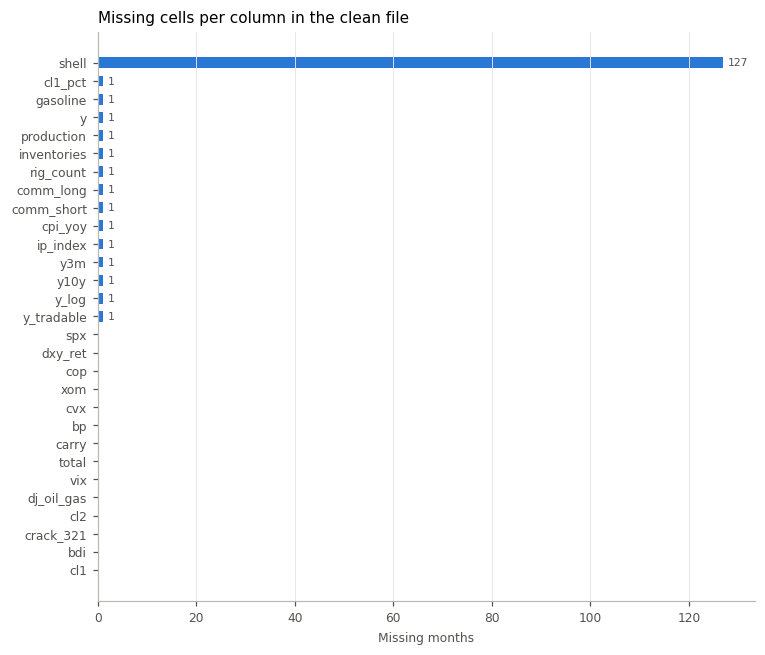

In [21]:
missing = chk[series_cols].isna().sum().sort_values()
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(missing.index, missing.values, color=C_BLUE, height=0.6)
for name, n in missing.items():
    if n > 0:
        ax.text(n + 1, name, str(n), va="center", fontsize=7, color=C_INK)
ax.set_xlabel("Missing months")
ax.set_title("Missing cells per column in the clean file")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

**Every series over time.** One panel per column; shading marks validation (light) and test (dark). Look for breaks, flat stretches or jumps that aren't real events.

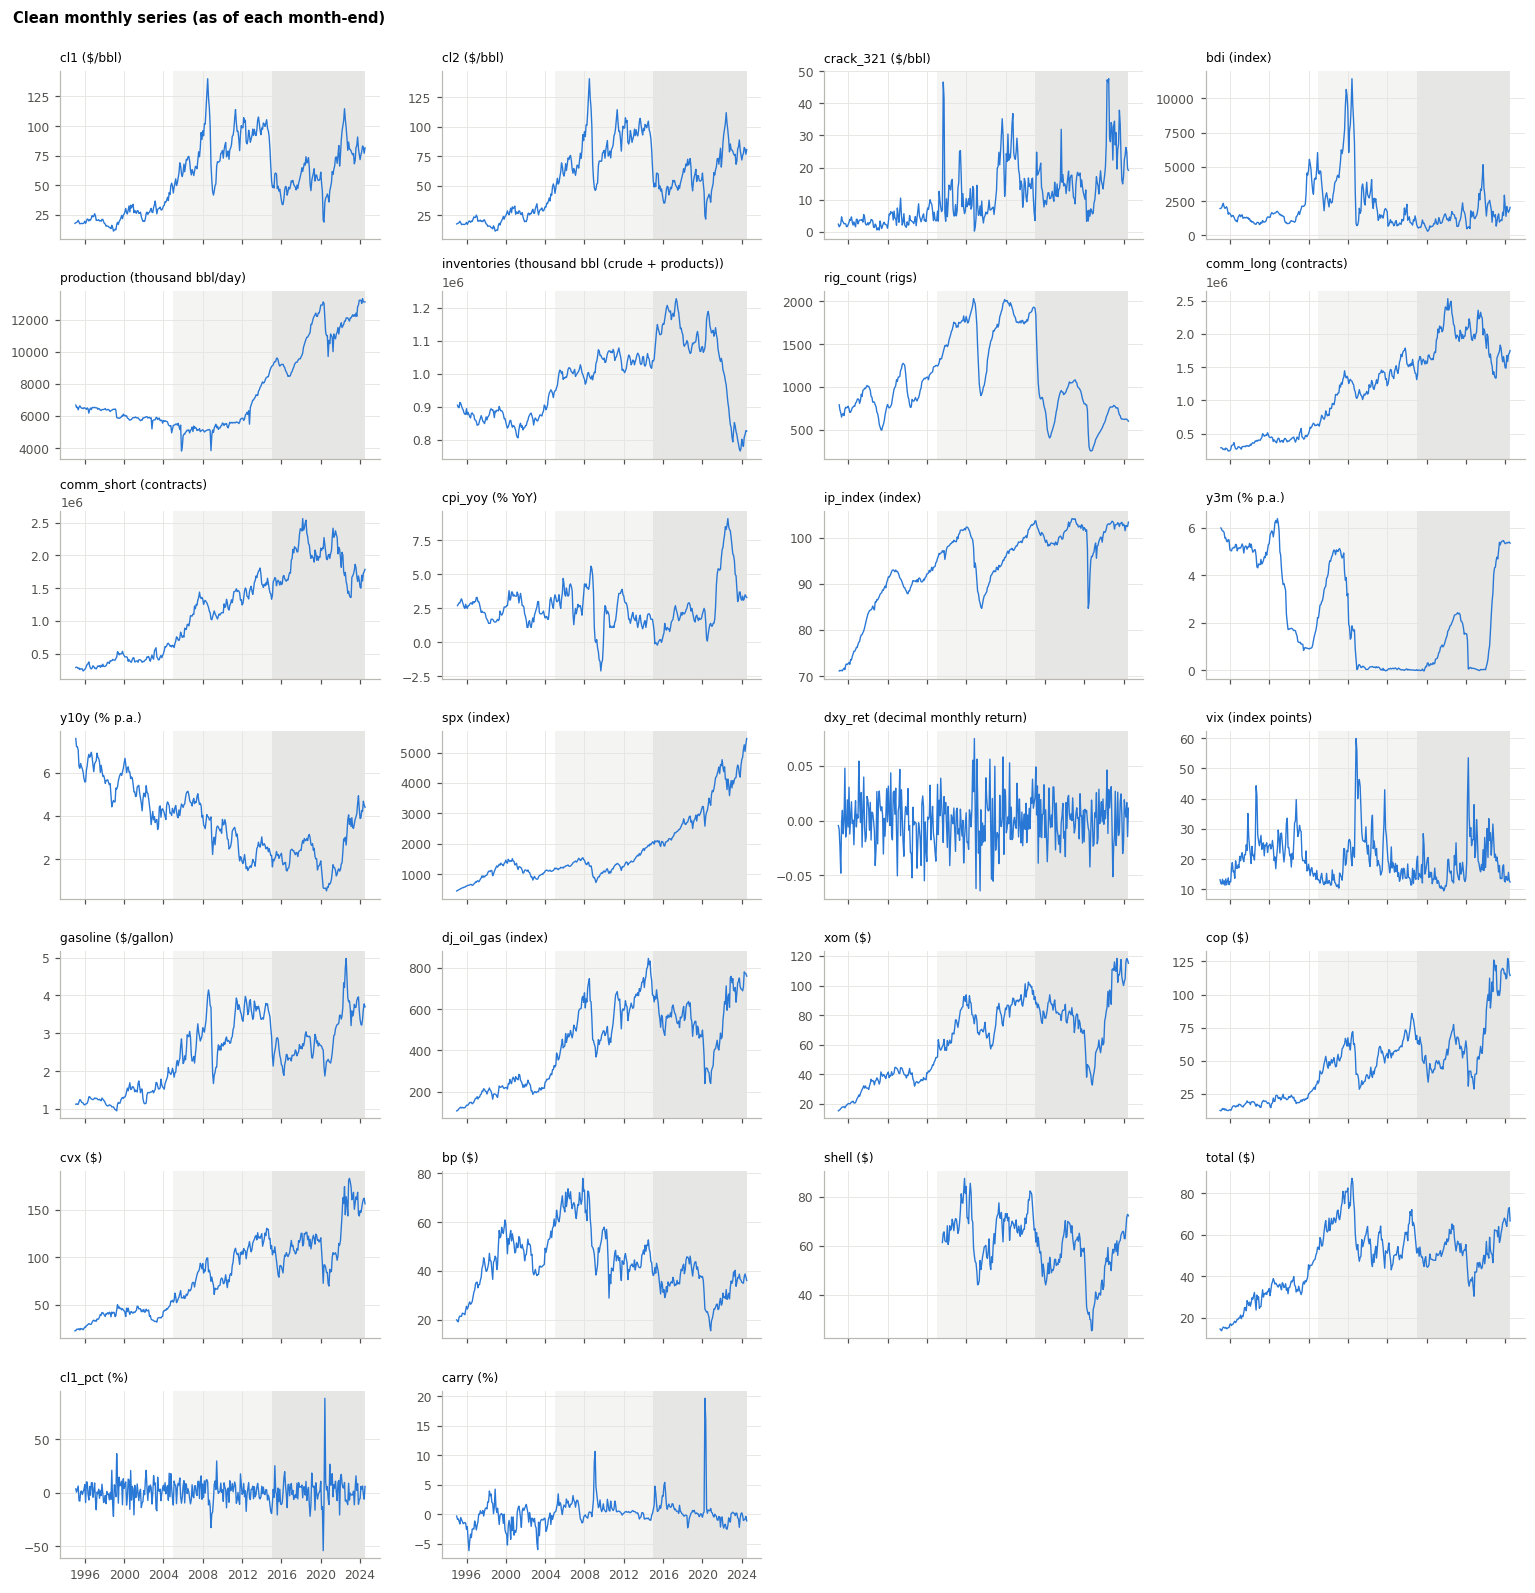

In [22]:
def shade_windows(ax):
    ax.axvspan(pd.Timestamp(TRAIN_END), pd.Timestamp(VALID_END), color=C_GREY, alpha=0.15, linewidth=0)
    ax.axvspan(pd.Timestamp(VALID_END), chk.index.max(), color=C_GREY, alpha=0.35, linewidth=0)

panel_cols = [c for c in series_cols if c not in ("y", "y_log", "y_tradable")]
ncols = 4
nrows = int(np.ceil(len(panel_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 2.1 * nrows), sharex=True)
for ax, col in zip(axes.flat, panel_cols):
    ax.plot(chk.index, chk[col], color=C_BLUE, linewidth=0.9)
    shade_windows(ax)
    ax.set_title(f"{col} ({UNITS.get(col, '%')})", fontsize=8)
for ax in axes.flat[len(panel_cols):]:
    ax.set_visible(False)
fig.suptitle("Clean monthly series (as of each month-end)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()

**The target.** `y` (generic CL1 % change) against `y_tradable` (holding one contract). They track each other; the gap is the carry, widest in 2008–09 and 2020.

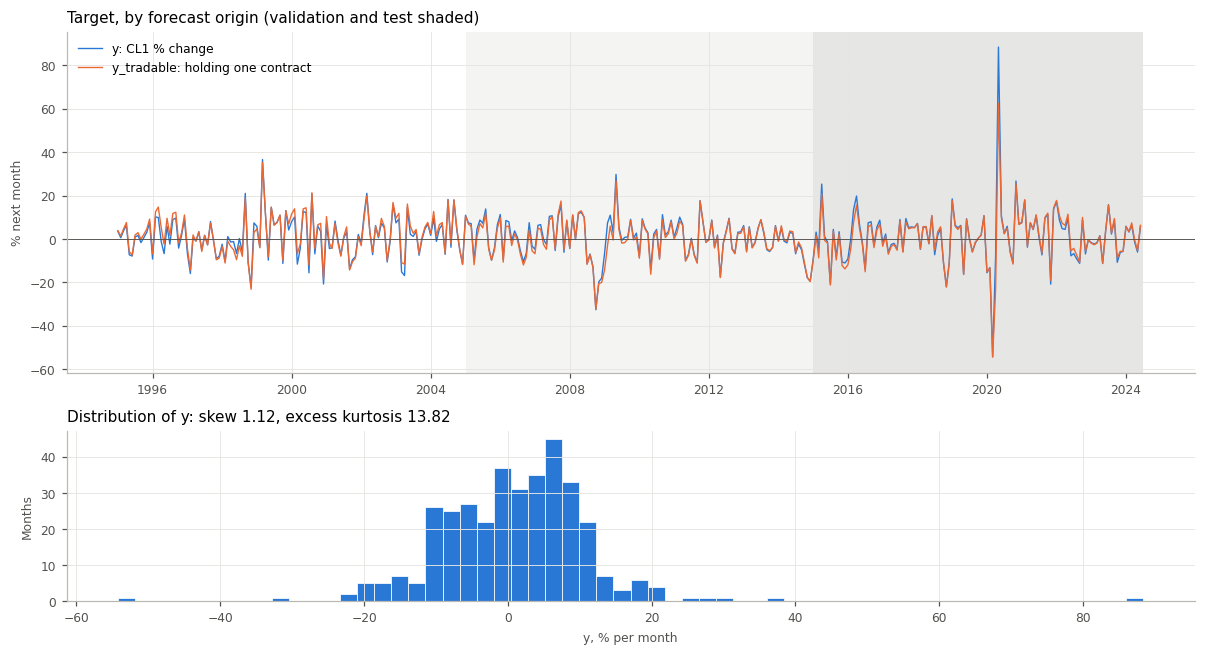

In [23]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), gridspec_kw={"height_ratios": [2, 1]})
ax = axes[0]
ax.plot(chk.index, chk["y"], color=C_BLUE, linewidth=0.9, label="y: CL1 % change")
ax.plot(chk.index, chk["y_tradable"], color=C_ORANGE, linewidth=0.9, label="y_tradable: holding one contract")
ax.axhline(0, color=C_INK, linewidth=0.6)
shade_windows(ax)
ax.set_ylabel("% next month")
ax.set_title("Target, by forecast origin (validation and test shaded)")
ax.legend(loc="upper left", frameon=False)

ax = axes[1]
ax.hist(chk["y"].dropna(), bins=60, color=C_BLUE, edgecolor="white", linewidth=0.5)
ax.set_xlabel("y, % per month")
ax.set_ylabel("Months")
ax.set_title(f"Distribution of y: skew {chk['y'].skew():.2f}, excess kurtosis {chk['y'].kurt():.2f}")
fig.tight_layout()
plt.show()

**Release lag, visually.** Industrial production as published for each month vs the value the clean file uses at that month-end: the clean line is the raw line moved one month right.

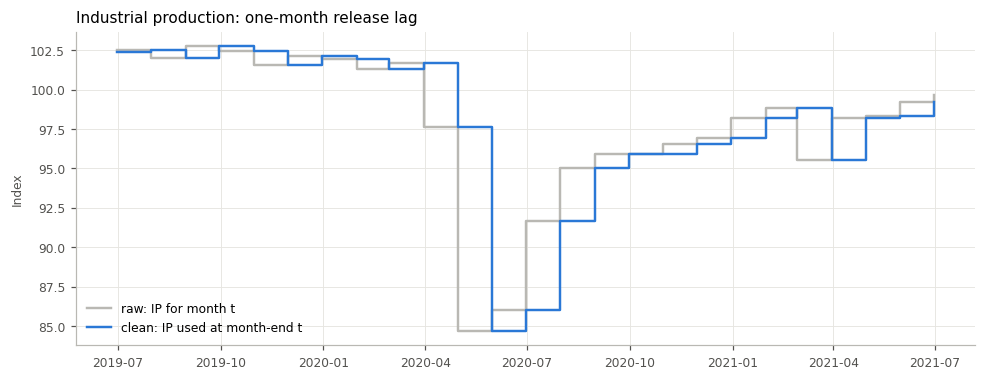

In [24]:
win = slice("2019-06-30", "2021-06-30")
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.step(ref.loc[win].index, ref.loc[win, "ip_index"], where="post", color=C_GREY, linewidth=1.6,
        label="raw: IP for month t")
ax.step(chk.loc[win].index, chk.loc[win, "ip_index"], where="post", color=C_BLUE, linewidth=1.6,
        label="clean: IP used at month-end t")
ax.set_ylabel("Index")
ax.set_title("Industrial production: one-month release lag")
ax.legend(loc="lower left", frameon=False)
fig.tight_layout()
plt.show()

**April 2020, visually.** Daily CL1 with the month-end values in the clean file on top. The −37.63 day sits inside April; the month-ends don't touch it.

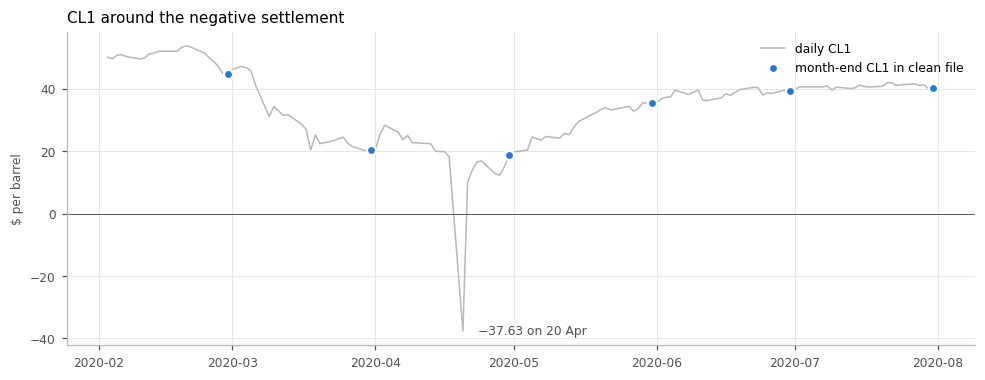

In [25]:
d = daily.loc["2020-02-01":"2020-07-31", "CL1"]
me = chk.loc["2020-02-29":"2020-07-31", "cl1"]
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(d.index, d, color=C_GREY, linewidth=1, label="daily CL1")
ax.scatter(me.index, me, color=C_BLUE, s=36, zorder=3, edgecolor="white", linewidth=1.5,
           label="month-end CL1 in clean file")
ax.axhline(0, color=C_INK, linewidth=0.6)
ax.annotate("−37.63 on 20 Apr", xy=(pd.Timestamp("2020-04-20"), -37.63), xytext=(10, 0),
            textcoords="offset points", va="center", fontsize=8, color=C_INK)
ax.set_ylabel("$ per barrel")
ax.set_title("CL1 around the negative settlement")
ax.legend(loc="upper right", frameon=False)
fig.tight_layout()
plt.show()

**Summary**
- Monthly, Dec 1994 to Jun 2024, 354 months with a target. Split by target month: train to Dec 2004, validation 2005–14, test Jan 2015 – Jun 2024 (114, same as the benchmark).
- Monthly sheets only, dates set to month-end, no gaps. Brent dropped (data error). Daily crack/BDI misaligned, monthly values used.
- Weekly and monthly rigs/COT/inventories differ in definition; monthly only.
- Market prices used in their own month; IP, CPI, production, inventories, rigs, COT and gasoline lagged one month. Treasury yields also lagged one month (dated one month early in the file).
- `Total Open Interest` dropped (it is Long + Short).
- No negative month-end price. Outliers flagged: Mar 2020 and May 2020.
- `y_tradable` = CL1(t+1)/CL2(t) − 1 for the trading rule.

## 3. Stationarity
*Felix (reviewed by Ronan).*

## 4. Predictors & variable selection
*Div.*

## 5. Models
*Mike, Ronan, Div.*

### 5.1 Felix's OLS: momentum, carry, dollar

$$y_{t+1} = \alpha + \beta_1\,\text{momentum}_t + \beta_2\,\text{carry}_t + \beta_3\,\text{dollar}_t + \varepsilon_{t+1}$$

| Signal | Definition at origin *t* | Why |
|---|---|---|
| `momentum` | this month's CL1 % change (`cl1_pct`) | short-term trend or reversal |
| `carry` | $100\,(CL1_t - CL2_t)/CL1_t$, + = backwardation (minus the clean file's `carry`) | curve shape: tight prompt market |
| `dollar` | $100 \times$ `dxy_ret` lagged one more month | oil is priced in dollars |

OLS with an intercept, no scaling or selection. Estimated on the **training window only** (target months 1995-02 to 2004-12). Standard errors are HAC (Newey–West, 3 lags) because monthly returns can be autocorrelated and heteroskedastic. Reads the saved clean CSV (`chk`), not objects in memory.

In [26]:
FX_FEATURES = ["momentum", "carry", "dollar"]
fx = pd.DataFrame(index=chk.index)
fx["target_month"] = chk["target_month"]
fx["sample"] = chk["sample"]
fx["actual"] = chk["y"]
fx["actual_tradable"] = chk["y_tradable"]
fx["momentum"] = chk["cl1_pct"]
fx["carry"] = 100 * (chk["cl1"] - chk["cl2"]) / chk["cl1"]      # + = backwardation
fx["dollar"] = 100 * chk["dxy_ret"].shift(1)

np.testing.assert_allclose(fx["carry"], -chk["carry"], atol=2e-6, rtol=0)
assert (pd.PeriodIndex(fx["target_month"], freq="M") == chk.index.to_period("M") + 1).all()
fx_usable = fx.dropna(subset=["actual"] + FX_FEATURES)

def fx_ols(rows, target="actual", hac=False):
    X = sm.add_constant(rows[FX_FEATURES], has_constant="add")
    m = sm.OLS(rows[target], X)
    return m.fit(cov_type="HAC", cov_kwds={"maxlags": 3}) if hac else m.fit()

fx_train = fx_usable[fx_usable["sample"] == "train"]
fx_fit = fx_ols(fx_train, hac=True)

# Same coefficients as Felix's handoff notebook
felix_handoff = pd.Series({"const": 1.756784, "momentum": -0.051880, "carry": -0.603438, "dollar": 0.278033})
assert np.allclose(fx_fit.params[felix_handoff.index], felix_handoff, atol=1e-5)

print(f"Training targets {fx_train['target_month'].iloc[0]} to {fx_train['target_month'].iloc[-1]} "
      f"({len(fx_train)} months; the first is lost to the dollar lag). Matches Felix's handoff: PASS")
print(f"R² {fx_fit.rsquared:.3f}, adjusted R² {fx_fit.rsquared_adj:.3f}")
pd.DataFrame({"coefficient": fx_fit.params, "HAC s.e.": fx_fit.bse, "t": fx_fit.tvalues, "p": fx_fit.pvalues})

Training targets 1995-02 to 2004-12 (119 months; the first is lost to the dollar lag). Matches Felix's handoff: PASS
R² 0.025, adjusted R² -0.001


,coefficient,HAC s.e.,t,p
const,1.757,1.126,1.560,0.119
momentum,-0.052,0.084,-0.620,0.535
carry,-0.603,0.535,-1.129,0.259
dollar,0.278,0.401,0.694,0.488


**Training fit.** No coefficient is significant (all |t| < 1.6) and adjusted R² is about zero. The signs: momentum slightly negative (reversal), carry negative, dollar positive. A weak in-sample fit is normal for monthly oil returns. What matters is whether the model forecasts out of sample (Section 7).

## 6. Diagnostics
*Div.*

## 7. Out-of-sample evaluation
*Ronan.*

### 7.1 Validation: Felix's OLS, 2005–2014

Scored on the **validation window only** (120 target months, Jan 2005 – Dec 2014). The test window is not used here.

**Two forecasting schemes**
- **Expanding (main):** at each origin *t*, re-estimated on every target already known (rows *s < t*, since row *s* holds the move in *s+1*). This is what a trader could actually have run.
- **Fixed:** the 5.1 training coefficients, never updated.

**Benchmarks:** zero change (a no-change price forecast means a 0% return) and the historical mean of past returns (also expanding).

**Metrics:** RMSE and MAE; out-of-sample $R^2_{OS} = 1 - \text{MSE}_{model}/\text{MSE}_{bench}$; hit rate (binomial test against 50%); Clark–West (one-sided; the right test because the model nests both benchmarks); Diebold–Mariano (two-sided, HAC).

In [27]:
fx_valid = fx_usable[fx_usable["sample"] == "validation"].copy()
fx_valid["fixed"] = fx_fit.predict(sm.add_constant(fx_valid[FX_FEATURES], has_constant="add"))

fx_pred, fx_mean, fx_paths = {}, {}, {}
for t in fx_valid.index:
    past = fx_usable[fx_usable.index < t]          # only targets already realised at t
    m = fx_ols(past)
    fx_pred[t] = float(m.predict(sm.add_constant(fx_valid.loc[[t], FX_FEATURES], has_constant="add")).iloc[0])
    fx_mean[t] = past["actual"].mean()
    fx_paths[fx_valid.loc[t, "target_month"]] = m.params
fx_valid["expanding"] = pd.Series(fx_pred)
fx_valid["hist_mean"] = pd.Series(fx_mean)
fx_valid["zero"] = 0.0
fx_paths = pd.DataFrame(fx_paths).T

assert len(fx_valid) == 120 and fx_valid[["expanding", "fixed", "hist_mean"]].notna().all().all()
assert fx_valid["target_month"].iloc[0] == "2005-01" and fx_valid["target_month"].iloc[-1] == "2014-12"
print(f"{len(fx_valid)} validation forecasts, {fx_valid['target_month'].iloc[0]} to {fx_valid['target_month'].iloc[-1]}")

120 validation forecasts, 2005-01 to 2014-12


In [28]:
def clark_west(y, f_model, f_bench, lags=3):
    """One-sided p-value; H0: the model adds nothing over the nested benchmark."""
    adj = (y - f_bench) ** 2 - ((y - f_model) ** 2 - (f_bench - f_model) ** 2)
    r = sm.OLS(adj.values, np.ones(len(adj))).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return 1 - stats.norm.cdf(r.tvalues[0])

def diebold_mariano(y, f_model, f_bench, lags=3):
    """Two-sided p-value; H0: equal mean squared error."""
    d = (y - f_bench) ** 2 - (y - f_model) ** 2
    r = sm.OLS(d.values, np.ones(len(d))).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return 2 * (1 - stats.norm.cdf(abs(r.tvalues[0])))

y_val = fx_valid["actual"]
rows = {}
for name in ["expanding", "fixed", "hist_mean", "zero"]:
    f = fx_valid[name]
    e = y_val - f
    row = {"RMSE": np.sqrt((e ** 2).mean()), "MAE": e.abs().mean(), "mean forecast": f.mean()}
    if name != "zero":
        hits = int((np.sign(f) == np.sign(y_val)).sum())
        row["hit rate"] = hits / len(y_val)
        row["hit p (binomial)"] = stats.binomtest(hits, len(y_val), 0.5, alternative="greater").pvalue
    if name in ("expanding", "fixed"):
        for b in ("zero", "hist_mean"):
            row[f"R²_OS vs {b}"] = 1 - (e ** 2).mean() / ((y_val - fx_valid[b]) ** 2).mean()
            row[f"CW p vs {b}"] = clark_west(y_val, f, fx_valid[b])
            row[f"DM p vs {b}"] = diebold_mariano(y_val, f, fx_valid[b])
    rows[name] = row
fx_scores = pd.DataFrame(rows)
fx_scores

,expanding,fixed,hist_mean,zero
RMSE,8.978,9.330,8.966,8.949
MAE,6.910,7.061,7.056,7.105
mean forecast,1.786,2.269,1.272,0.000
hit rate,0.567,0.558,0.550,NaN
hit p (binomial),0.085,0.118,0.158,NaN
R²_OS vs zero,-0.006,-0.087,NaN,NaN
CW p vs zero,0.190,0.505,NaN,NaN
DM p vs zero,0.913,0.356,NaN,NaN
R²_OS vs hist_mean,-0.003,-0.083,NaN,NaN
CW p vs hist_mean,0.299,0.787,NaN,NaN


**Where it wins and loses.** Cumulative squared-error difference against the zero benchmark: a rising line means the model is beating zero over that stretch, a falling line means it is losing.

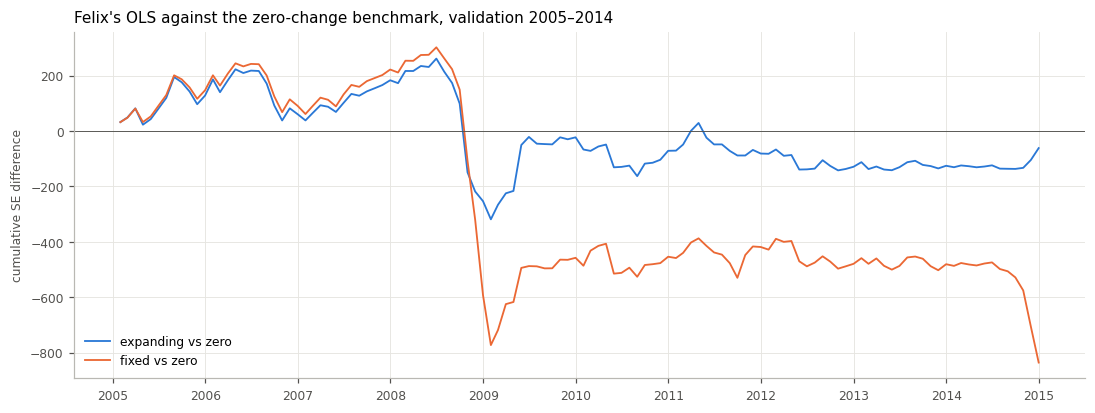

,R²_OS vs zero (expanding),hit rate (expanding)
year,,
2005,0.152,0.667
2006,-0.108,0.500
2007,0.149,0.667
2008,-0.165,0.250
2009,0.187,0.833
2010,-0.069,0.667
2011,-0.011,0.500
2012,-0.081,0.583
2013,0.011,0.500


In [29]:
vdates = pd.to_datetime(fx_valid["target_month"]) + MonthEnd(0)
fig, ax = plt.subplots(figsize=(10, 3.8))
for name, colour in [("expanding", C_BLUE), ("fixed", C_ORANGE)]:
    cssed = ((y_val - fx_valid["zero"]) ** 2 - (y_val - fx_valid[name]) ** 2).cumsum()
    ax.plot(vdates, cssed.values, color=colour, label=f"{name} vs zero")
ax.axhline(0, color=C_INK, linewidth=0.6)
ax.set_ylabel("cumulative SE difference")
ax.set_title("Felix's OLS against the zero-change benchmark, validation 2005–2014")
ax.legend(loc="lower left", frameon=False)
fig.tight_layout()
plt.show()

fx_valid.assign(year=fx_valid["target_month"].str[:4]).groupby("year").apply(
    lambda g: pd.Series({"R²_OS vs zero (expanding)": 1 - ((g["actual"] - g["expanding"]) ** 2).sum() / (g["actual"] ** 2).sum(),
                         "hit rate (expanding)": (np.sign(g["expanding"]) == np.sign(g["actual"])).mean()}))

**Coefficient stability.** Expanding-window estimates through the validation years. A stable sign is a precondition for trusting a signal.

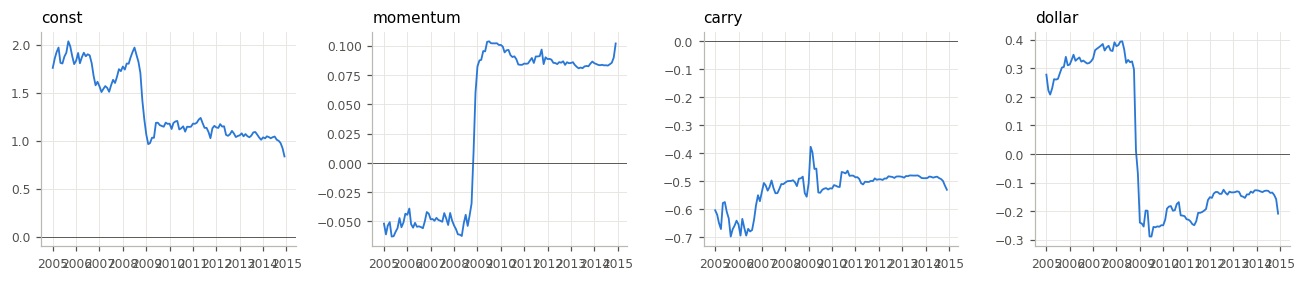

,const,momentum,carry,dollar
2005-01,1.757,-0.052,-0.603,0.278
2009-12,1.173,0.101,-0.525,-0.250
2014-12,0.835,0.102,-0.530,-0.209


In [30]:
fig, axes = plt.subplots(1, 4, figsize=(12, 2.6), sharex=True)
for ax, c in zip(axes, fx_paths.columns):
    ax.plot(pd.to_datetime(fx_paths.index), fx_paths[c], color=C_BLUE)
    ax.axhline(0, color=C_INK, linewidth=0.6)
    ax.set_title(c)
fig.tight_layout()
plt.show()
fx_paths.iloc[[0, 59, -1]]

**Is carry a real signal or the roll?** `y` is the *generic* CL1 change, so it includes the monthly switch to the next contract. From 2.6, $(1+y) = (1+y_{tradable})(1 - \text{carry}/100)$ with Felix's sign. If the tradable return were unpredictable, carry would still get a coefficient near −1 on `y`, purely from the roll. Re-running on `y_tradable` separates the two.

In [31]:
roll_check = {}
for s in ["train", "validation"]:
    rows_s = fx_usable[fx_usable["sample"] == s].dropna(subset=["actual_tradable"])
    for tgt in ["actual", "actual_tradable"]:
        r = fx_ols(rows_s, target=tgt, hac=True)
        roll_check[(s, "y" if tgt == "actual" else "y_tradable")] = {
            "carry coef": r.params["carry"], "carry p": r.pvalues["carry"],
            "momentum coef": r.params["momentum"], "dollar coef": r.params["dollar"]}
pd.DataFrame(roll_check).T

carry coef  carry p  momentum coef  dollar coef
train      y               -0.603    0.259         -0.052        0.278
           y_tradable       0.395    0.466         -0.052        0.268
validation y               -0.748    0.057          0.300       -0.524
           y_tradable       0.216    0.574          0.297       -0.521

**Findings: Felix's OLS on validation**
- **No significant out-of-sample skill.** The expanding version is roughly level with the zero benchmark (R²_OS ≈ −0.6%, RMSE 8.98 vs 8.95; slightly better MAE). The fixed version is clearly worse (R²_OS ≈ −8.7%). Clark–West does not reject at 5% against either benchmark.
- **Hit rate 57% (p ≈ 0.09):** suggestive, not significant.
- **It's a 2008 story.** The model beats zero steadily from 2005 to mid-2008, then gives it all back in the late-2008 crash: the positive constant keeps forecasting gains while oil falls (hit rate 25% in 2008). Flat after 2009. The fixed version also loses in late 2014, at the start of the OPEC price war.
- **Unstable signals.** Momentum flips from −0.05 to +0.10 and dollar from +0.28 to −0.21 over the window. Only carry keeps its sign.
- **Carry is mostly the roll.** On `y_tradable` the carry coefficient moves by about +1 and loses significance. The carry 'signal' on `y` comes from the generic series rolling contracts, so it can't be traded. **The trading rule (Section 8) must be scored on `y_tradable`.**

## 8. Trading rule
*Mike.*

## 9. Conclusion